# KM–PIKFNN 混合型中心斜裂纹：同时求解 $K_I$ 与 $K_{II}$

实现用户所给文献 §5.4 / Fig.15 / Table 5 的算例：板宽 $H=4$、板高 $2H=8$、中心裂纹半长 $a=1$，平面应力，$\nu=0.3$，上下边均匀拉应力取 $\sigma_0=1$，左右边无牵引。裂纹与水平轴夹角为 $15^\circ,30^\circ,45^\circ,60^\circ$。所有数值采用一致单位，$K$ 的量纲为应力乘长度平方根。

延续一型、二型程序：外部基本解 + 首阶及高阶 KM–Williams 富集，列归一化，SVD 热启动，可选 Adam/L-BFGS，按最低损失恢复系数。**不生成裂尖源点圈，不把参考 SIF 放入损失、初始化或参数选择。**

斜裂纹不适用一/二型的四分之一模型。这里沿裂纹延长线分为 $\Omega_1$ 与 $\Omega_2$，利用中心反演对称性求解上方子域；两侧韧带严格匹配位移和牵引。子域的人工源点边界位于该子域外部；其中底部源点可位于另一物理子域内，但不参与该子域的场评价。

In [2]:
import math
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lstsq
try:
    import torch
except ImportError:
    torch = None

cfg = {
    "a":1.0, "H":4.0, "E":1.0, "nu":0.3, "sigma0":1.0,
    "angles_deg":(15,30,45,60),
    "n_source_per_edge":80, "source_offset":0.3,
    "n_outer":151, "n_crack":151, "n_interface_each":121,
    "higher_orders":(1.5,2.5),
    "lambda_reg":1e-10, "svd_rcond":1e-12,
    "ls_warm_start":True, "adam_steps":500, "adam_lr":1e-3,
    "lbfgs_epochs":50, "lbfgs_max_iter":20,
    "plot_angle":30, "nx_plot":101, "ny_plot":201,
    "save_outputs":False, "output_dir":"mixed_mode_results", "seed":2026,
}
a,H,E,nu,sigma0=(float(cfg[k]) for k in ("a","H","E","nu","sigma0"))
mu=E/(2*(1+nu));kappa=(3-nu)/(1+nu)  # Plane stress
lam=E*nu/(1-nu**2)                    # Reduced in-plane Lame constant
assert 0<a<H/2 and E>0 and -1<nu<0.5
np.random.seed(cfg["seed"])
if torch is not None:
    torch.set_default_dtype(torch.float64)
    torch.manual_seed(cfg["seed"])
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device="cpu"
print("Complex basis: CPU NumPy; coefficient training:",
      device if torch is not None else "SciPy SVD only (PyTorch unavailable)")

# Right-tip references transcribed from the supplied Table 5.
# These dictionaries are read ONLY after the boundary problem is solved.
BEM_REF={15:(1.9705,0.4641),30:(1.6020,0.8180),45:(1.0838,0.9666),60:(0.5494,0.8551)}
PINN_REF={15:(1.9715,0.4696),30:(1.6058,0.8205),45:(1.0904,0.9618),60:(0.5441,0.8592)}

def maybe_save(fig,name):
    if cfg["save_outputs"]:
        folder=Path(cfg["output_dir"]);folder.mkdir(parents=True,exist_ok=True)
        fig.savefig(folder/name,dpi=600,bbox_inches="tight")

Complex basis: CPU NumPy; coefficient training: cuda


## 复势、坐标旋转与裂尖系数
每个裂尖采用向裂纹前方指向的局部坐标 $w=e^{-i\alpha}(z-z_t)$。右尖 $\alpha=\theta$，左尖 $\alpha=\theta+\pi$。
\[
\phi_p^I=\frac{H^{1/2-p}}{\sqrt{2\pi}}w^p,\quad\psi_p^I=(1-p)\phi_p^I,
\qquad
\phi_p^{II}=-\frac{iH^{1/2-p}}{\sqrt{2\pi}}w^p,\quad\psi_p^{II}=-(p+1)\phi_p^{II}.
\]
在每个裂尖局部原点直接应用 KM 公式，再将位移向量、应力张量旋转回整体坐标，因此不需要遗漏或另补整体坐标的平移项。$p=1/2$ 单位场的系数分别为 $K_I,K_{II}$。最后四列顺序固定为 **右尖 KI、右尖 KII、左尖 KI、左尖 KII**。

对 $\Omega_1$，右尖取 $0\leq\arg w\leq\pi$，左尖取 $-\pi\leq\arg w\leq0$。代码显式指定裂面分支，避免浮点零的符号导致错误裂面值。

In [3]:
def km(z,phi,dp,ddp,psi,dpsi):
 s=4*dp.real;d=2*(z.conj()*ddp+dpsi);u=(kappa*phi-z*dp.conj()-psi.conj())/(2*mu)
 return np.array([u.real,u.imag,(s-d.real)/2,(s+d.real)/2,d.imag/2]).T

def force(z,s,P):
 q=z-s;den=2*np.pi*(kappa+1)
 phi=-P/den*np.log(q)+P/(2*np.pi*kappa*(kappa+1));dp=-P/den/q;ddp=P/den/q**2
 psi=kappa*P.conjugate()/den*np.log(q)+P*s.conjugate()/den/q
 dpsi=kappa*P.conjugate()/den/q-P*s.conjugate()/den/q**2
 return km(z,phi,dp,ddp,psi,dpsi)

def rotate(f,angle):
 c,s=np.cos(angle),np.sin(angle);ux,uy,xx,yy,xy=f.T
 return np.array([c*ux-s*uy,s*ux+c*uy,c*c*xx+s*s*yy-2*c*s*xy,s*s*xx+c*c*yy+2*c*s*xy,c*s*(xx-yy)+(c*c-s*s)*xy]).T

def will(z,angle,side,mode,p):
 # right angle, left angle+pi; local w origin at each tip
 tip=side*a*np.exp(1j*angle);orientation=angle+(np.pi if side==-1 else 0)
 w=(z-tip)*np.exp(-1j*orientation)
 # enforce intended upper/lower face branch despite floating-point rotation noise
 phase = np.arctan2(np.maximum(w.imag,0),w.real) if side==1 else -np.arctan2(np.maximum(-w.imag,0),w.real)
 def power(q):return np.abs(w)**q*np.exp(1j*q*phase)
 C=(1 if mode=='I' else -1j)/np.sqrt(2*np.pi)*H**(.5-p)
 phi=C*power(p);dp=C*p*power(p-1);ddp=C*p*(p-1)*power(p-2)
 factor=(1-p) if mode=='I' else -(p+1)
 return rotate(km(w,phi,dp,ddp,factor*phi,factor*dp),orientation)

def solve(theta=30,n=80,nb=151,nface=151,nint=121,orders=(1.5,2.5),margin=.3,reg=1e-10,verbose=True):
 ang=np.deg2rad(theta);c,s=np.cos(ang),np.sin(ang);lim=H/2/c
 vertices=np.array([-H/2-1j*H/2*np.tan(ang),H/2+1j*H/2*np.tan(ang),H/2+1j*H,-H/2+1j*H])
 # convex polygon offset to create continuous exterior artificial boundary
 edges=np.roll(vertices,-1)-vertices; normals=-1j*edges/abs(edges)
 vo=[]
 for i in range(4):
  # intersect two offset lines at vertex
  e1=edges[i-1];e2=edges[i];p1=vertices[i]+margin*normals[i-1];p2=vertices[i]+margin*normals[i]
  M=np.array([[e1.real,-e2.real],[e1.imag,-e2.imag]])
  t=np.linalg.solve(M,np.array([(p2-p1).real,(p2-p1).imag]))[0]
  vo.append(p1+t*e1)
 vo=np.array(vo);src=np.concatenate([vo[i]+(np.arange(n)+.5)/n*(vo[(i+1)%4]-vo[i]) for i in range(4)])
 def line(v1,v2,N):return v1+(np.arange(N)+.5)/N*(v2-v1)
 pts={'top':line(vertices[3],vertices[2],nb),'right':line(vertices[1],vertices[2],nb),'left':line(vertices[0],vertices[3],nb),'crack':line(-.999*a,.999*a,nface)*np.exp(1j*ang),'int':np.r_[line(-lim,-1.001*a,nint),line(1.001*a,lim,nint)]*np.exp(1j*ang)}
 def basis(z):
  cols=[force(z,ss,P) for ss in src for P in (1+0j,1j)]
  cols +=[will(z,ang,side,mode,p) for p in orders for side in (1,-1) for mode in ('I','II')]
  cols +=[will(z,ang,side,mode,.5) for side in (1,-1) for mode in ('I','II')]
  return np.stack(cols,axis=2)
 rows=[];rhs=[]
 def add(block,target=0,weight=1):
  f=np.sqrt(weight/len(block));rows.append(f*block);rhs.append(np.full(len(block),f*target))
 for key in ['top','right','left']:
  mat=basis(pts[key]);add(mat[:,3 if key=='top' else 2],sigma0 if key=='top' else 0);add(mat[:,4])
 mat=basis(pts['crack']);nx,ny=-s,c
 tx=nx*mat[:,2]+ny*mat[:,4];ty=nx*mat[:,4]+ny*mat[:,3]
 add(tx,weight=4);add(ty,weight=4)
 z=pts['int'];m=basis(z);mm=basis(-z)
 add(m[:,0]+mm[:,0],weight=2);add(m[:,1]+mm[:,1],weight=2)
 add(nx*(m[:,2]-mm[:,2])+ny*(m[:,4]-mm[:,4]),weight=2)
 add(nx*(m[:,4]-mm[:,4])+ny*(m[:,3]-mm[:,3]),weight=2)
 # Pure traction problem retains a rigid rotation; fix one gauge only.
 add(basis(np.array([1j*H]))[:,0],weight=1)
 A=np.vstack(rows);y=np.concatenate(rhs);scale=np.linalg.norm(A,axis=0);An=A/scale
 R=np.eye(An.shape[1])[:-4]*np.sqrt(reg/(An.shape[1]-4))
 tt,_,rank,sv=lstsq(np.vstack([An,R]),np.r_[y,np.zeros(len(R))],cond=cfg['svd_rcond'],lapack_driver='gelsd');coeff=tt/scale
 loss=np.linalg.norm(A@coeff-y)**2
 if verbose:print(theta,'n',n,'K right/left',coeff[-4:],'loss',loss,flush=True)
 return dict(theta=theta,coeff=coeff,src=src,vertices=vertices,source_vertices=vo,basis=basis,points=pts,A=An,rhs=y,scale=scale,loss=loss,theta_svd=tt,rank=int(rank),reg=reg,orders=orders,angle_rad=ang,margin=margin,nb=nb,nface=nface,nint=nint)

## 连接条件与唯一性
中心反演对称性给出 $\mathbf u_2(z)=-\mathbf u_1(-z)$，$\boldsymbol\sigma_2(z)=\boldsymbol\sigma_1(-z)$。裂纹延长线、裂纹外的两段韧带上施加
\[
\mathbf u_1(z)+\mathbf u_1(-z)=0,\qquad
[\boldsymbol\sigma_1(z)-\boldsymbol\sigma_1(-z)]\mathbf n=0.
\]
裂面施加 $\boldsymbol\sigma_1\mathbf n=0$。所有外边界按整体坐标的法向施加拉伸或自由牵引。纯牵引问题保留一个刚体转动，以上边中点 $u_x=0$ 固定转动规范；该条件不影响应力和 SIF。

In [4]:
def objective_numpy(case,theta):
    theta=np.asarray(theta).reshape(-1)
    return float(np.sum((case["A"]@theta-case["rhs"])**2)+
                 case["reg"]*np.mean(theta[:-4]**2))

def train_case(case):
    # Identical regularized linear objective to the SVD assembly.
    if torch is None:
        case["theta_final"]=case["theta_svd"].copy()
        case["best_origin"]="SciPy SVD; Adam/L-BFGS NOT run"
        case["history"]=[objective_numpy(case,case["theta_final"])]
        return case
    n=case["A"].shape[1]
    theta=torch.nn.Parameter(torch.zeros(n,device=device))
    At=torch.as_tensor(case["A"],device=device)
    bt=torch.as_tensor(case["rhs"],device=device)
    def objective():
        return torch.sum((At@theta-bt)**2)+case["reg"]*torch.mean(theta[:-4]**2)
    if cfg["ls_warm_start"]:
        with torch.no_grad(): theta.copy_(torch.as_tensor(case["theta_svd"],device=device))
    best_loss=objective().item();best_theta=theta.detach().clone()
    best_origin="SVD initialization" if cfg["ls_warm_start"] else "zero initialization"
    history=[best_loss]
    def record(label):
        nonlocal best_loss,best_theta,best_origin
        value=objective().item();history.append(value)
        if value<best_loss:
            best_loss,best_theta,best_origin=value,theta.detach().clone(),label
    if cfg["adam_steps"]:
        print(f"  Adam: {cfg['adam_steps']} steps")
        opt=torch.optim.Adam([theta],lr=cfg["adam_lr"])
        for epoch in range(cfg["adam_steps"]):
            opt.zero_grad();loss=objective();loss.backward();opt.step()
            record(f"Adam {epoch+1}")
    with torch.no_grad():theta.copy_(best_theta)
    if cfg["lbfgs_epochs"]:
        print(f"  L-BFGS: {cfg['lbfgs_epochs']} outer iterations")
        opt=torch.optim.LBFGS([theta],lr=1.,max_iter=cfg["lbfgs_max_iter"],
                             max_eval=cfg["lbfgs_max_iter"]+10,history_size=100,
                             tolerance_grad=1e-12,tolerance_change=1e-14,line_search_fn="strong_wolfe")
        for epoch in range(cfg["lbfgs_epochs"]):
            def closure():
                opt.zero_grad();value=objective();value.backward();return value
            opt.step(closure);record(f"L-BFGS {epoch+1}")
    case["theta_final"]=best_theta.cpu().numpy().copy()
    case["coeff"]=case["theta_final"]/case["scale"]
    case["best_origin"]=best_origin;case["history"]=history
    return case

cases={}
for angle in cfg["angles_deg"]:
    t0=time.perf_counter()
    case=solve(angle,n=cfg["n_source_per_edge"],nb=cfg["n_outer"],
               nface=cfg["n_crack"],nint=cfg["n_interface_each"],
               orders=cfg["higher_orders"],margin=cfg["source_offset"],
               reg=cfg["lambda_reg"],verbose=False)
    cases[angle]=train_case(case)
    case["elapsed"]=time.perf_counter()-t0
    print(f"theta={angle:2d} deg: KI={case['coeff'][-4]:.10f}, KII={case['coeff'][-3]:.10f}, "
          f"objective={objective_numpy(case,case['theta_final']):.3e}, time={case['elapsed']:.2f}s")
    print("  Lowest-loss coefficients:",case["best_origin"])

  Adam: 500 steps
  L-BFGS: 50 outer iterations
theta=15 deg: KI=1.9723234280, KII=0.4641271626, objective=4.204e-11, time=2.77s
  Lowest-loss coefficients: SVD initialization
  Adam: 500 steps
  L-BFGS: 50 outer iterations
theta=30 deg: KI=1.6033890792, KII=0.8186401476, objective=4.266e-11, time=1.03s
  Lowest-loss coefficients: SVD initialization
  Adam: 500 steps
  L-BFGS: 50 outer iterations
theta=45 deg: KI=1.0844722769, KII=0.9675075248, objective=3.382e-11, time=1.00s
  Lowest-loss coefficients: SVD initialization
  Adam: 500 steps
  L-BFGS: 50 outer iterations
theta=60 deg: KI=0.5492184714, KII=0.8556611272, objective=2.680e-11, time=1.01s
  Lowest-loss coefficients: SVD initialization


## 与文献表 5 对比
以 BEM 行作为主要数值参考，同时保留文献 PINNs 行。表中的 $K_I,K_{II}$ 是右裂尖值。参考表是有限板数值解，不是无限板公式；这里不使用无限板 $\cos^2\theta$ / $\sin\theta\cos\theta$ 作为有限板参考。

Angle | KI computed | KI BEM | err KI | KII computed | KII BEM | err KII
   15 | 1.9723234 | 1.9705 | 0.0925% | 0.4641272 | 0.4641 | 0.0059%
   30 | 1.6033891 | 1.6020 | 0.0867% | 0.8186401 | 0.8180 | 0.0783%
   45 | 1.0844723 | 1.0838 | 0.0620% | 0.9675075 | 0.9666 | 0.0939%
   60 | 0.5492185 | 0.5494 | 0.0330% | 0.8556611 | 0.8551 | 0.0656%


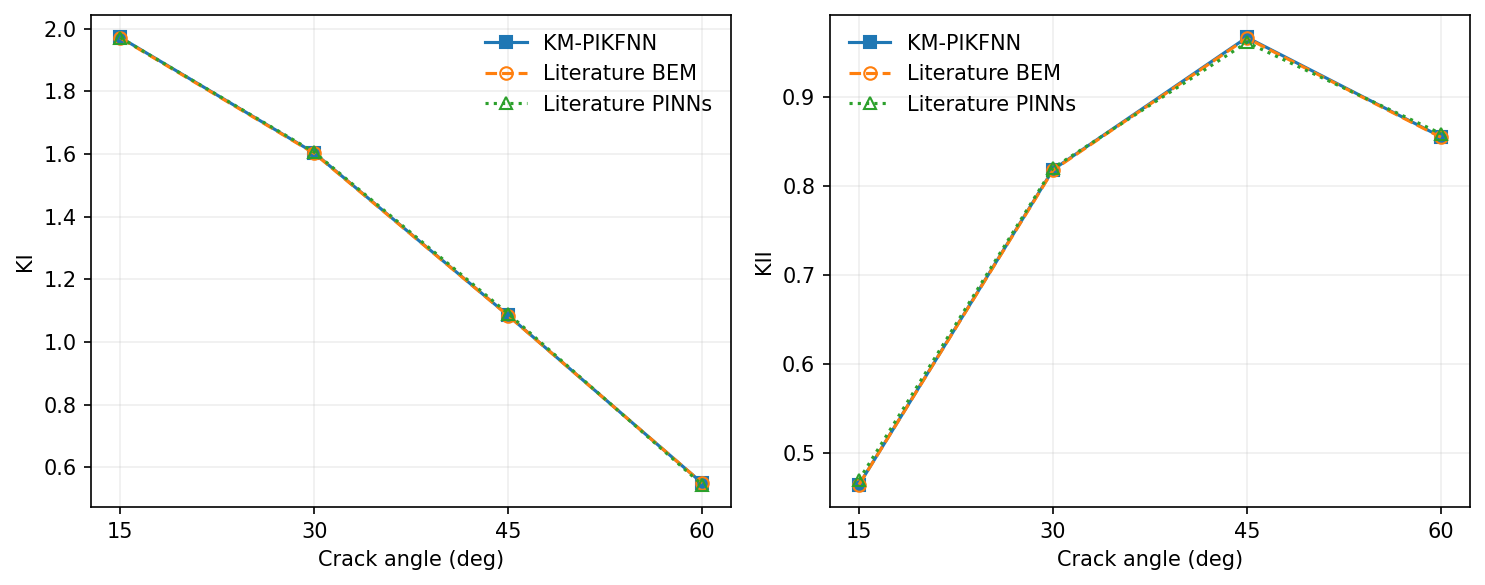

In [5]:
if not (np.isclose(a,1) and np.isclose(H,4) and np.isclose(nu,.3)):
    raise ValueError("The supplied reference table applies to a=1,H=4,nu=0.3 only")
comparison=[]
print("Angle | KI computed | KI BEM | err KI | KII computed | KII BEM | err KII")
for angle,case in cases.items():
    ki,kii=case["coeff"][-4:-2]
    ri,rii=np.asarray(BEM_REF[angle])*sigma0
    pi,pii=np.asarray(PINN_REF[angle])*sigma0
    row=dict(angle=angle,KI=ki,KII=kii,KI_BEM=ri,KII_BEM=rii,
             KI_PINN=pi,KII_PINN=pii,err_KI=abs(ki-ri)/abs(ri),
             err_KII=abs(kii-rii)/abs(rii))
    comparison.append(row)
    print(f"{angle:5d} | {ki:.7f} | {ri:.4f} | {row['err_KI']:.4%} | "
          f"{kii:.7f} | {rii:.4f} | {row['err_KII']:.4%}")

angles=np.array(list(cases))
fig,axes=plt.subplots(1,2,figsize=(10,4),dpi=150)
for ax,q in zip(axes,("KI","KII")):
    ax.plot(angles,[r[q] for r in comparison],"s-",label="KM-PIKFNN")
    ax.plot(angles,[r[q+"_BEM"] for r in comparison],"o--",mfc="none",label="Literature BEM")
    ax.plot(angles,[r[q+"_PINN"] for r in comparison],"^:",mfc="none",label="Literature PINNs")
    ax.set_xlabel("Crack angle (deg)");ax.set_ylabel(q);ax.set_xticks(angles)
    ax.grid(alpha=.2);ax.legend(frameon=False)
fig.tight_layout();maybe_save(fig,"sif_comparison.png");plt.show()

## 域内本构核查、独立边界点与裂尖极限
使用新的边界配点核查残差。右裂尖前方的局部 $\sigma_{nn}$ 与 $\sigma_{tn}$ 分别提取 $K_I,K_{II}$；上裂面局部 $u_n,u_t$ 的 $\sqrt r$ 系数提供第二种独立提取。位移拟合包含常数项，防止刚体分量污染裂尖极限。

In [6]:
def evaluate_upper(case,z,batch_size=1200):
    z=np.asarray(z,dtype=np.complex128).reshape(-1)
    parts=[]
    for start in range(0,len(z),batch_size):
        mat=case["basis"](z[start:start+batch_size])
        parts.append(np.einsum("nqc,c->nq",mat,case["coeff"]))
    return np.vstack(parts)

def evaluate_full(case,z,batch_size=1200):
    z=np.asarray(z,dtype=np.complex128).reshape(-1)
    local=z*np.exp(-1j*case["angle_rad"])
    upper=local.imag>=0
    out=np.empty((len(z),5))
    if upper.any():out[upper]=evaluate_upper(case,z[upper],batch_size)
    if (~upper).any():
        lower=evaluate_upper(case,-z[~upper],batch_size)
        lower[:,:2]*=-1
        out[~upper]=lower
    return out

def independent_boundary_checks(case,N=203):
    v=case["vertices"];ang=case["angle_rad"];nx,ny=-np.sin(ang),np.cos(ang)
    def line(p,q,n):return p+(np.arange(n)+.37)/n*(q-p)
    residuals={}
    for name,p,q in (("top",v[3],v[2]),("right",v[1],v[2]),("left",v[0],v[3])):
        f=evaluate_upper(case,line(p,q,N))
        target=sigma0 if name=="top" else 0
        vals=np.c_[f[:,3 if name=="top" else 2]-target,f[:,4]]
        residuals[name+"_traction_rms"]=float(np.sqrt(np.mean(vals**2)))
    z=line(-.999*a,.999*a,N)*np.exp(1j*ang)
    f=evaluate_upper(case,z)
    vals=np.c_[nx*f[:,2]+ny*f[:,4],nx*f[:,4]+ny*f[:,3]]
    residuals["crack_traction_rms"]=float(np.sqrt(np.mean(vals**2)))
    limit=H/2/np.cos(ang)
    z=np.r_[line(-limit,-1.001*a,N),line(1.001*a,limit,N)]*np.exp(1j*ang)
    f=evaluate_upper(case,z);fm=evaluate_upper(case,-z);diff=f-fm
    residuals["interface_displacement_rms"]=float(np.sqrt(np.mean((f[:,:2]+fm[:,:2])**2)))
    vals=np.c_[nx*diff[:,2]+ny*diff[:,4],nx*diff[:,4]+ny*diff[:,3]]
    residuals["interface_traction_rms"]=float(np.sqrt(np.mean(vals**2)))
    return residuals

def constitutive_check():
    mismatches=[]
    for mode in ("I","II"):
        for side in (1,-1):
            ang=np.deg2rad(30);orientation=ang+(np.pi if side==-1 else 0)
            z=side*a*np.exp(1j*ang)+np.exp(1j*orientation)*np.array([.3+side*.2j,.5+side*.4j])
            def f(zz):return will(zz,ang,side,mode,.5)
            delta=1e-6*a
            dx=(f(z+delta)-f(z-delta))/(2*delta)
            dy=(f(z+1j*delta)-f(z-1j*delta))/(2*delta)
            exx,eyy,gamma=dx[:,0],dy[:,1],dy[:,0]+dx[:,1]
            derived=np.c_[(lam+2*mu)*exx+lam*eyy,lam*exx+(lam+2*mu)*eyy,mu*gamma]
            exact=f(z)[:,2:]
            mismatches.append(np.linalg.norm(derived-exact)/np.linalg.norm(exact))
    return max(mismatches)
print("Unit enrichment maximum Hooke relative mismatch:",constitutive_check())
assert constitutive_check()<1e-7

for angle,case in cases.items():
    print(f"\nAngle {angle}: independent residuals:",independent_boundary_checks(case))
    r=a*np.geomspace(1e-6,1e-3,25);ang=case["angle_rad"];tip=a*np.exp(1j*ang)
    ahead=rotate(evaluate_upper(case,tip+r*np.exp(1j*ang)),-ang)
    face=rotate(evaluate_upper(case,tip-r*np.exp(1j*ang)),-ang)
    kis=np.sqrt(2*np.pi*r)*ahead[:,3]
    kiis=np.sqrt(2*np.pi*r)*ahead[:,4]
    t=np.sqrt(r/a);V=np.c_[np.ones_like(t),t,t**2,t**3,t**4]
    # Fit both local displacement components together; coefficient of sqrt(r/a).
    fit=lstsq(V,face[:,:2],cond=1e-13,lapack_driver="gelsd")[0]
    factor=2*mu/(kappa+1)*np.sqrt(2*np.pi/a)
    kid,kiid=factor*fit[1,1],factor*fit[1,0]
    case["checks"]=dict(r=r,KI_stress=kis,KII_stress=kiis,KI_displacement=kid,KII_displacement=kiid)
    print(f"  KI : coefficient={case['coeff'][-4]:.9f}, stress={kis[0]:.9f}, face-fit={kid:.9f}")
    print(f"  KII: coefficient={case['coeff'][-3]:.9f}, stress={kiis[0]:.9f}, face-fit={kiid:.9f}")

Unit enrichment maximum Hooke relative mismatch: 1.465544162314294e-10

Angle 15: independent residuals: {'top_traction_rms': 7.056104351377153e-07, 'right_traction_rms': 3.443858666522038e-07, 'left_traction_rms': 3.3657315662142235e-07, 'crack_traction_rms': 4.2702053056620747e-07, 'interface_displacement_rms': 6.207106212153494e-07, 'interface_traction_rms': 2.810292419099134e-07}
  KI : coefficient=1.972323428, stress=1.972324858, face-fit=1.972323436
  KII: coefficient=0.464127163, stress=0.464127646, face-fit=0.464127162

Angle 30: independent residuals: {'top_traction_rms': 6.876789194250707e-07, 'right_traction_rms': 3.1148101863914467e-07, 'left_traction_rms': 3.649190793626828e-07, 'crack_traction_rms': 5.187940363603429e-07, 'interface_displacement_rms': 5.947593956979001e-07, 'interface_traction_rms': 3.0256571864360255e-07}
  KI : coefficient=1.603389079, stress=1.603390103, face-fit=1.603389089
  KII: coefficient=0.818640148, stress=0.818640903, face-fit=0.818640148

Angl

## 源点数量收敛（可选）
固定几何、配点和富集阶数，只改变每条人工边界上的源点数量。输出不替换主计算模型，不按参考值筛选结果。

In [7]:
def source_convergence(angle=60,counts=(48,64,80)):
    results=[]
    for n in counts:
        case=solve(angle,n=n,nb=cfg["n_outer"],nface=cfg["n_crack"],
                   nint=cfg["n_interface_each"],orders=cfg["higher_orders"],
                   margin=cfg["source_offset"],reg=cfg["lambda_reg"],verbose=False)
        ki,kii=case["coeff"][-4:-2]
        results.append((n,ki,kii,case["loss"]))
        print(f"n/edge={n}: KI={ki:.9f}, KII={kii:.9f}, boundary loss={case['loss']:.3e}")
    return results
# Uncomment for a convergence study:
# convergence=source_convergence()

## 源点与全板应力场
源点图显示用于上方子域的实际人工边界和全部源点；全板云图由中心反演重建下方场。裂纹两面的位移允许跳跃，裂纹外韧带通过连接条件连续。

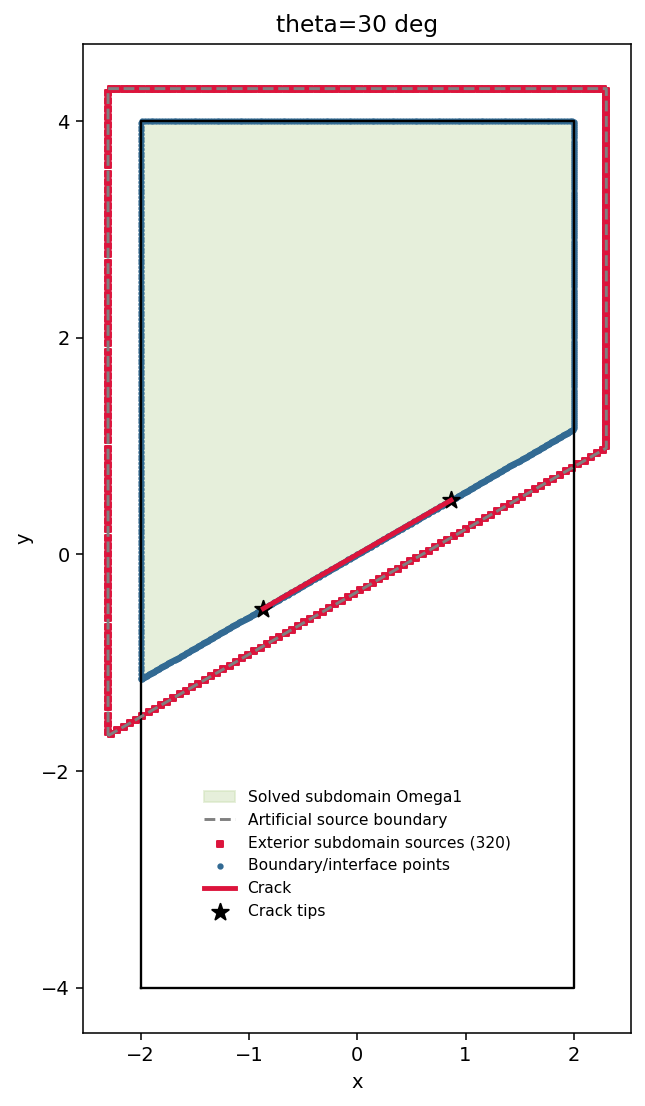

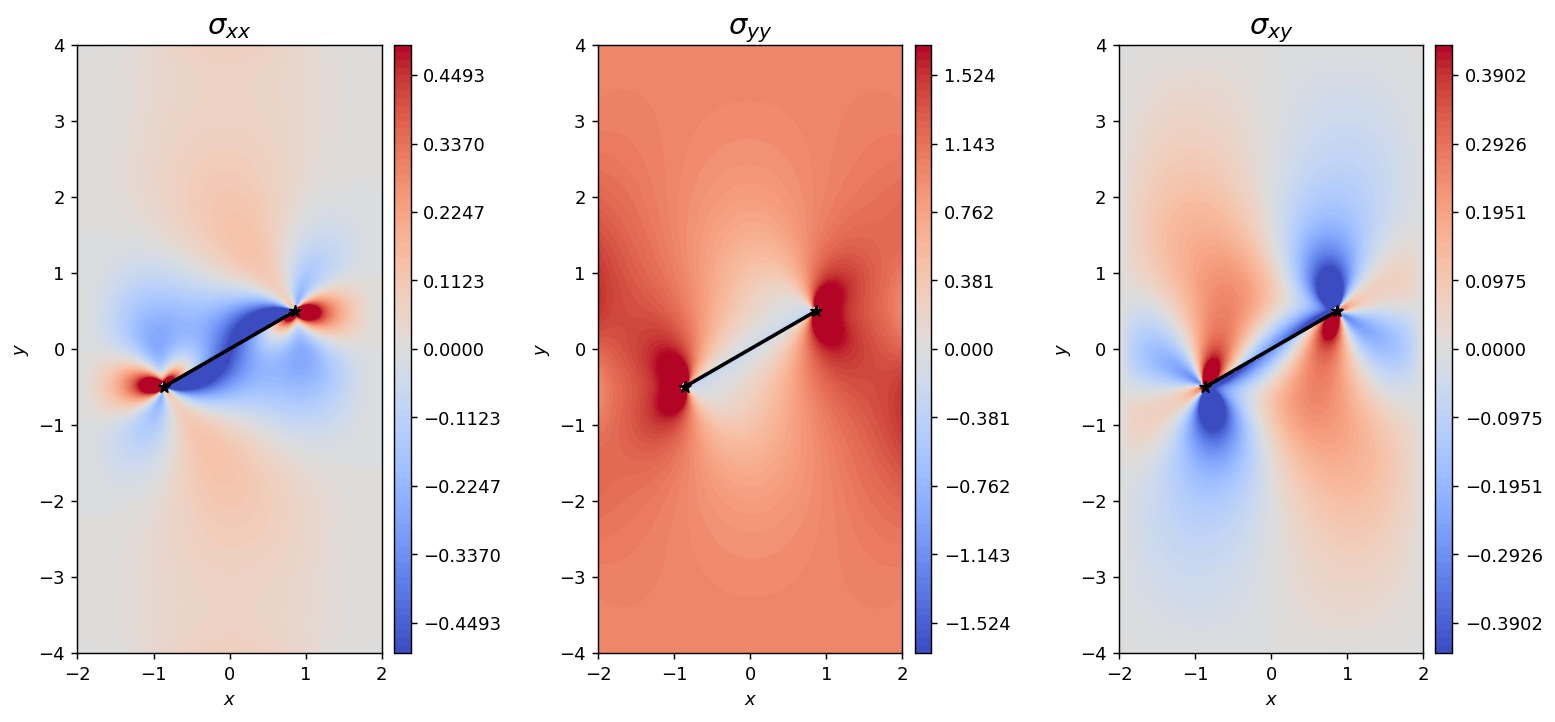

In [10]:
case=cases[cfg["plot_angle"]]
angle=case["angle_rad"];tips=np.array([-a,a])*np.exp(1j*angle)
fig,ax=plt.subplots(figsize=(6,8),dpi=140)
ax.plot([-H/2,H/2,H/2,-H/2,-H/2],[-H,-H,H,H,-H],"k-",lw=1.2)
v=case["vertices"];sv=case["source_vertices"]
ax.fill(v.real,v.imag,color="#CFE1B8",alpha=.5,label="Solved subdomain Omega1")
ax.plot(np.r_[sv.real,sv[0].real],np.r_[sv.imag,sv[0].imag],"--",color="gray",label="Artificial source boundary")
sources=case["src"]
ax.scatter(sources.real,sources.imag,s=9,color="crimson",marker="s",label=f"Exterior subdomain sources ({len(sources)})")
for i,z in enumerate(case["points"].values()):
    ax.scatter(z.real,z.imag,s=5,color="#326A93",label="Boundary/interface points" if i==0 else None)
ax.plot(tips.real,tips.imag,color="crimson",lw=2.5,label="Crack")
ax.scatter(tips.real,tips.imag,s=80,marker="*",color="black",label="Crack tips")
ax.set_aspect("equal");ax.set_xlabel("x");ax.set_ylabel("y");ax.set_title(f"theta={cfg['plot_angle']} deg")
ax.legend(loc="center",bbox_to_anchor=(.5,.18),frameon=False,fontsize=8);fig.tight_layout();maybe_save(fig,"sources.png");plt.show()

X,Y=np.meshgrid(np.linspace(-H/2,H/2,cfg["nx_plot"]),np.linspace(-H,H,cfg["ny_plot"]))
z=(X+1j*Y).ravel();distance=np.minimum(abs(z-tips[0]),abs(z-tips[1]))
local=z*np.exp(-1j*angle)
# Hide the crack line and small neighborhoods of both singular tips.
safe=(distance>.04*a)&~((abs(local.imag)<.005*a)&(abs(local.real)<a))
f=evaluate_full(case,z[safe]);fields=np.full((len(z),5),np.nan);fields[safe]=f
fig, axes = plt.subplots(1, 3, figsize=(12, 6), dpi=130)
fig.subplots_adjust(
    left=0.06, right=0.93, bottom=0.12, top=0.90, wspace=0.65
)

for ax, i, label in zip(
    axes, (2, 3, 4),
    (r"$\sigma_{xx}$", r"$\sigma_{yy}$", r"$\sigma_{xy}$")
):
    data = fields[:, i].reshape(X.shape)
    vmax = max(float(np.nanpercentile(abs(data), 98.5)), 1e-12)

    im = ax.contourf(
        X, Y, data,
        levels=np.linspace(-vmax, vmax, 81),
        cmap="coolwarm", extend="both"
    )

    ax.plot(tips.real, tips.imag, "k-", lw=2)
    ax.scatter(
        tips.real, tips.imag, s=40, marker="*", color="black"
    )
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(label, fontsize=16)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")

    # [左侧位置, 底部位置, 宽度, 高度]，相对于云图轴
    cax = ax.inset_axes([1.04, 0.0, 0.055, 1.0])
    fig.colorbar(
        im, cax=cax, extendrect=True, extendfrac=0
    )

maybe_save(fig, "stress_fields.png")
plt.show()

if cfg["save_outputs"]:
    import csv
    folder=Path(cfg["output_dir"]);folder.mkdir(parents=True,exist_ok=True)
    with (folder/"sif_comparison.csv").open("w",newline="",encoding="utf-8-sig") as stream:
        writer=csv.DictWriter(stream,fieldnames=list(comparison[0]))
        writer.writeheader();writer.writerows(comparison)
    for angle,case in cases.items():
        np.savez(folder/f"case_{angle}deg.npz",coefficients=case["coeff"],sources=case["src"],
                 KI=case["coeff"][-4],KII=case["coeff"][-3],angle=angle,**case["checks"])

文献来源：*Enriched physics-informed neural networks for 2D in-plane crack analysis: Theory and MATLAB code*, International Journal of Solids and Structures (2023), [ScienceDirect](https://www.sciencedirect.com/science/article/abs/pii/S0020768323002184)。几何、角度与参考值以用户提供的 §5.4、Fig.15、Table 5 截图为准。

解释验证范围：无 PyTorch 环境下，全 notebook 通过 SciPy SVD 路径执行；该结果是同一线性核系数模型、同一边界目标的直接求解。PyTorch 分支保留 Adam/L-BFGS，但不能将 SVD 热启动后的精度全部归因于训练，也不能把与 BEM 数值表的差异称为严格解析误差。